In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

## Importing the data

In [2]:
df = pd.read_csv("demand_forecasting.csv")
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [3]:
df.shape

(76000, 16)

In [4]:
df.columns

Index(['Date', 'Store ID', 'Product ID', 'Category', 'Region',
       'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount',
       'Weather Condition', 'Promotion', 'Competitor Pricing', 'Seasonality',
       'Epidemic', 'Demand'],
      dtype='str')

In [5]:
df.dtypes

Date                      str
Store ID                  str
Product ID                str
Category                  str
Region                    str
Inventory Level         int64
Units Sold              int64
Units Ordered           int64
Price                 float64
Discount                int64
Weather Condition         str
Promotion               int64
Competitor Pricing    float64
Seasonality               str
Epidemic                int64
Demand                  int64
dtype: object

In [6]:
df.describe()

,Inventory Level,Units Sold,Units Ordered,Price,Discount,Promotion,Competitor Pricing,Epidemic,Demand
count,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000
mean,301.062842,88.827316,89.090645,67.726028,9.087039,0.328947,69.454029,0.200000,104.317158
std,226.510161,43.994525,162.404627,39.377899,7.475781,0.469834,40.943818,0.400003,46.964801
min,0.000000,0.000000,0.000000,4.740000,0.000000,0.000000,4.290000,0.000000,4.000000
25%,136.000000,58.000000,0.000000,31.997500,5.000000,0.000000,32.620000,0.000000,71.000000
50%,227.000000,84.000000,0.000000,64.500000,10.000000,0.000000,65.700000,0.000000,100.000000
75%,408.000000,114.000000,121.000000,95.830000,10.000000,1.000000,97.932500,0.000000,133.000000
max,2267.000000,426.000000,1616.000000,228.030000,25.000000,1.000000,261.220000,1.000000,430.000000


## Assessing and Cleaning the Data

#### Checking for Missing Values 

In [7]:
df.isna().any()

Date                  False
Store ID              False
Product ID            False
Category              False
Region                False
Inventory Level       False
Units Sold            False
Units Ordered         False
Price                 False
Discount              False
Weather Condition     False
Promotion             False
Competitor Pricing    False
Seasonality           False
Epidemic              False
Demand                False
dtype: bool

In [8]:
df.isna().sum()

Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Price                 0
Discount              0
Weather Condition     0
Promotion             0
Competitor Pricing    0
Seasonality           0
Epidemic              0
Demand                0
dtype: int64

This dataset shows that there are no missing values in any of the columns. This means that my key variables of Inventory Level, Units Sold, Units Ordered, and Demand have data in each row. This is helpful because I will not need to evaluate whether to fill the missing values with a place holder such as NA or 0. This makes the data cleaner and prevents future inaccuracies caused by mixing data types of having incorrect 0 values impacting trends. 

#### Checking for Duplicates

In [9]:
df.duplicated(subset=None, keep='first')

0        False
1        False
2        False
3        False
4        False
         ...  
75995    False
75996    False
75997    False
75998    False
75999    False
Length: 76000, dtype: bool

In [10]:
print(df.duplicated().sum())

0


In [11]:
print(df.drop_duplicates())

             Date Store ID Product ID     Category Region  Inventory Level  \
0      2022-01-01     S001      P0001  Electronics  North              195   
1      2022-01-01     S001      P0002     Clothing  North              117   
2      2022-01-01     S001      P0003     Clothing  North              247   
3      2022-01-01     S001      P0004  Electronics  North              139   
4      2022-01-01     S001      P0005    Groceries  North              152   
...           ...      ...        ...          ...    ...              ...   
75995  2024-01-30     S005      P0016         Toys  North              233   
75996  2024-01-30     S005      P0017         Toys  North              137   
75997  2024-01-30     S005      P0018     Clothing  North              197   
75998  2024-01-30     S005      P0019    Furniture  North              125   
75999  2024-01-30     S005      P0020         Toys  North              126   

       Units Sold  Units Ordered   Price  Discount Weather Cond

There are no duplcates in my data meaning that each row is unique. This means that there are no days that were repeated for my key variables of Inventory Levels, Units Sold, Units Ordered, or Demand. It is important for these variables to not have duplicate days becuase it would cause incorrect changes to the running totals and impact the trends and eventual predictions. I would remove duplicate values to prevent these possible discrepencies in the data. 

### Checking for Outliers in Key Variables

#### Inventory Level 

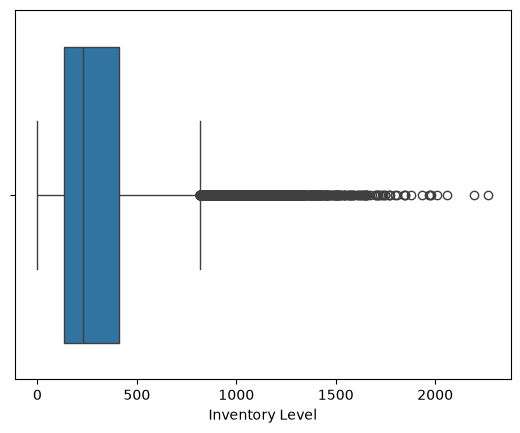

In [12]:
sns.boxplot(data=df, x="Inventory Level")
plt.show()

In [13]:
#calculating the IQR
Q1_inventory = df["Inventory Level"].quantile(0.25)
Q3_inventory = df["Inventory Level"].quantile(0.75)
IQR_inventory = Q3_inventory-Q1_inventory

In [14]:
#counting the number of outliers
inventory_outlier = df[((df["Inventory Level"]<Q1_inventory-1.5*IQR_inventory))|(df["Inventory Level"]>(Q3_inventory+1.5*IQR_inventory))]
inventory_outlier_count = inventory_outlier.count()
print(inventory_outlier_count)

Date                  2759
Store ID              2759
Product ID            2759
Category              2759
Region                2759
Inventory Level       2759
Units Sold            2759
Units Ordered         2759
Price                 2759
Discount              2759
Weather Condition     2759
Promotion             2759
Competitor Pricing    2759
Seasonality           2759
Epidemic              2759
Demand                2759
dtype: int64


#### Units Sold

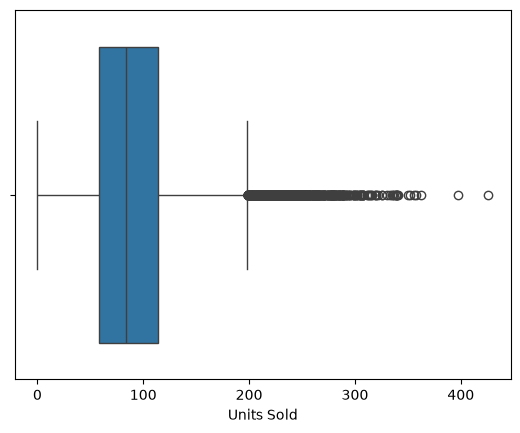

In [15]:
sns.boxplot(data=df, x="Units Sold")
plt.show()

In [16]:
#calculating the IQR
Q1_sold = df["Units Sold"].quantile(0.25)
Q3_sold = df["Units Sold"].quantile(0.75)
IQR_sold = Q3_sold-Q1_sold

In [17]:
#counting the number of outliers
sold_outlier = df[((df["Units Sold"]<Q1_sold-1.5*IQR_sold))|(df["Units Sold"]>(Q3_sold+1.5*IQR_sold))]
sold_outlier_count = sold_outlier.count()
print(sold_outlier_count)

Date                  1411
Store ID              1411
Product ID            1411
Category              1411
Region                1411
Inventory Level       1411
Units Sold            1411
Units Ordered         1411
Price                 1411
Discount              1411
Weather Condition     1411
Promotion             1411
Competitor Pricing    1411
Seasonality           1411
Epidemic              1411
Demand                1411
dtype: int64


#### Units Ordered

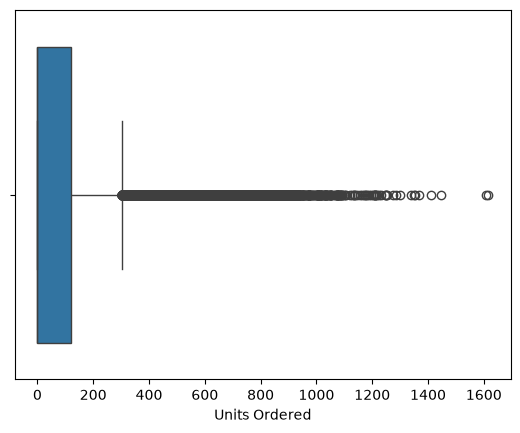

In [18]:
sns.boxplot(data=df, x="Units Ordered")
plt.show()

In [19]:
#calculating the IQR
Q1_ordered = df["Units Ordered"].quantile(0.25)
Q3_ordered = df["Units Ordered"].quantile(0.75)
IQR_ordered = Q3_ordered-Q1_ordered

In [20]:
#counting the number of outliers
ordered_outlier = df[((df["Units Ordered"]<Q1_ordered-1.5*IQR_ordered))|(df["Units Ordered"]>(Q3_ordered+1.5*IQR_ordered))]
ordered_outlier_count = ordered_outlier.count()
print(ordered_outlier_count)

Date                  7524
Store ID              7524
Product ID            7524
Category              7524
Region                7524
Inventory Level       7524
Units Sold            7524
Units Ordered         7524
Price                 7524
Discount              7524
Weather Condition     7524
Promotion             7524
Competitor Pricing    7524
Seasonality           7524
Epidemic              7524
Demand                7524
dtype: int64


#### Demand 

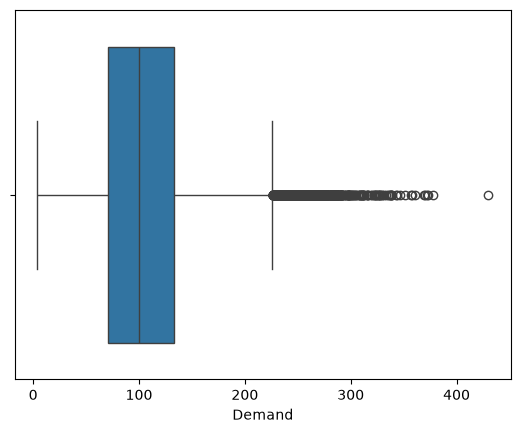

In [21]:
sns.boxplot(data=df, x="Demand")
plt.show()

In [22]:
#calculating the IQR
Q1_demand = df["Demand"].quantile(0.25)
Q3_demand = df["Demand"].quantile(0.75)
IQR_demand = Q3_demand-Q1_demand

In [23]:
#counting the number of outliers
demand_outlier = df[((df["Demand"]<Q1_demand-1.5*IQR_demand))|(df["Demand"]>(Q3_demand+1.5*IQR_demand))]
demand_outlier_count = demand_outlier.count()
print(demand_outlier_count)

Date                  986
Store ID              986
Product ID            986
Category              986
Region                986
Inventory Level       986
Units Sold            986
Units Ordered         986
Price                 986
Discount              986
Weather Condition     986
Promotion             986
Competitor Pricing    986
Seasonality           986
Epidemic              986
Demand                986
dtype: int64


The boxplots and IQR calculations reveal that there is a significant number of outliers in this dataset with there being up to 16% of the data points being outliers. Since these are key variables it is important to address these outliers to prevent them from skewing my data and predictions. There are various options such as directly removing the outliers, capping values to a specific percentile, or substituting the entries with another form of measument such as mean or median. I do not was to outrightly delete all of the values since 16% is a significant portion of my total data. For outliers in Inventory Levels and Units Ordered I will consider capping the values or using the mean since these variables are comprised of more than 2-3% outliers. However, this risks a loss in data variablity and may create a blind spot for my predictive models later on. For the other key variables of Units Sold and Demand I will consider removing these outliers since they make up less than 3% of the data points. However, this creates the risk of generating bias in my model and so I will continue to consider other options. 

#### Handling Outliers 

#### Inventory 

In [24]:
# Setting the lower and upper limit 
lower_inventory = df["Inventory Level"].quantile(0.05)
upper_inventory = df["Inventory Level"].quantile(0.95) 

In [25]:
# Capping Inventory Level within the set range
df["Inventory Level"] = df["Inventory Level"].clip(lower=lower_inventory)
df["Inventory Level"] = df["Inventory Level"].clip(upper=upper_inventory)

#### Units Sold

In [26]:
# Setting the lower and upper limit 
lower_sold = df["Units Sold"].quantile(0.05)
upper_sold = df["Units Sold"].quantile(0.95) 

In [27]:
# Capping Unit Sold within the set range
df["Units Sold"] = df["Units Sold"].clip(lower=lower_sold)
df["Units Sold"] = df["Units Sold"].clip(upper=upper_sold)

#### Units Ordered

In [28]:
# Setting the lower and upper limit 
lower_ordered = df["Units Ordered"].quantile(0.05)
upper_ordered = df["Units Ordered"].quantile(0.95) 

In [29]:
# Capping Unit Ordered within the set range
df["Units Ordered"] = df["Units Ordered"].clip(lower=lower_ordered)
df["Units Ordered"] = df["Units Ordered"].clip(upper=upper_ordered)

#### Demand 

In [30]:
# Setting the lower and upper limit 
lower_demand = df["Demand"].quantile(0.05)
upper_demand = df["Demand"].quantile(0.95) 

In [31]:
# Capping Demand within the set range
df["Demand"] = df["Demand"].clip(lower=lower_demand)
df["Demand"] = df["Demand"].clip(upper=upper_demand)

#### Justification
I decided to cap each of the key variables at thier 5th and 95th percentiles as a way to address outliers. I did this becuase there was a significant amount of outliers in my data, up to 16% of all rows. I did not want to delete that amount of valuable data without knowing if it was done in error or if it were actually extreme values. Additionally, I did not want to substitute each of the outlier variables with central tendency measurments becuase I still wanted data points that would reflect the significant increase or decrease in the value. These key variable were already skewed and so I thought capping the outliers at the 5th and 95th percentiles was in the best interest for a semblance of accuracy in visualizations, analysis, and future predictions. 

### Checking for Inconsistencies in Categorical Variables

In [32]:
df["Category"].value_counts()

Category
Groceries      30400
Furniture      13680
Clothing       12160
Toys           10640
Electronics     9120
Name: count, dtype: int64

In [33]:
df["Region"].value_counts()

Region
North    30400
South    15200
East     15200
West     15200
Name: count, dtype: int64

In [34]:
df["Weather Condition"].value_counts()

Weather Condition
Cloudy    24360
Sunny     22980
Rainy     17500
Snowy     11160
Name: count, dtype: int64

In [35]:
df["Seasonality"].value_counts()

Seasonality
Winter    21000
Spring    18400
Summer    18400
Autumn    18200
Name: count, dtype: int64

These lists of the different values under each cateorical column shows how there are no inconsistencies in the data. None of the columns show any unknown or inconsistant spelling of the variable options. While these are not part of my key variables, it is still important to have these categorical variables cleaned to avoid running into future issues. For example, it is important to have these variables cleaned in case future analysis ties in any of these categories. 

Previous cleaning errors have been corrected and this pipeline has successful execution and is ready for modeling. 

## Exploratory Analysis 

#### Distribution 

<Axes: >

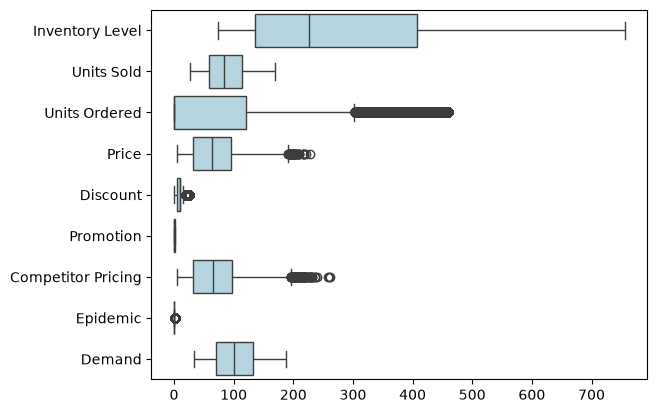

In [36]:
#show distribution of all numerical variables 
sns.boxplot(data=df, color="lightblue", orient="h")

<Axes: >

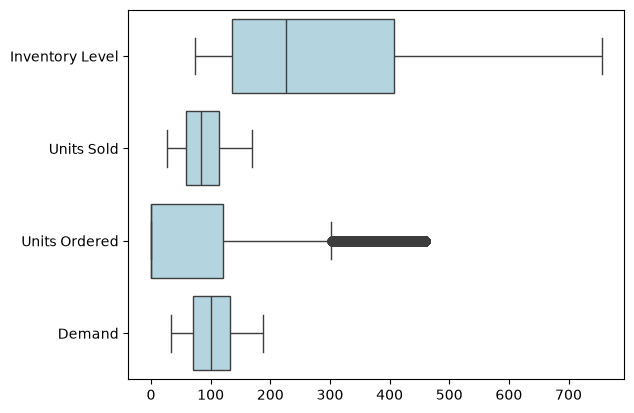

In [37]:
#show distribution of key variables including my target variable of "Inventory Level"
sns.boxplot(data=df[["Inventory Level", "Units Sold", "Units Ordered", "Demand"]], color='lightblue', orient='h')

#### Possible Relationships 

<Axes: xlabel='Date', ylabel='Inventory Level'>

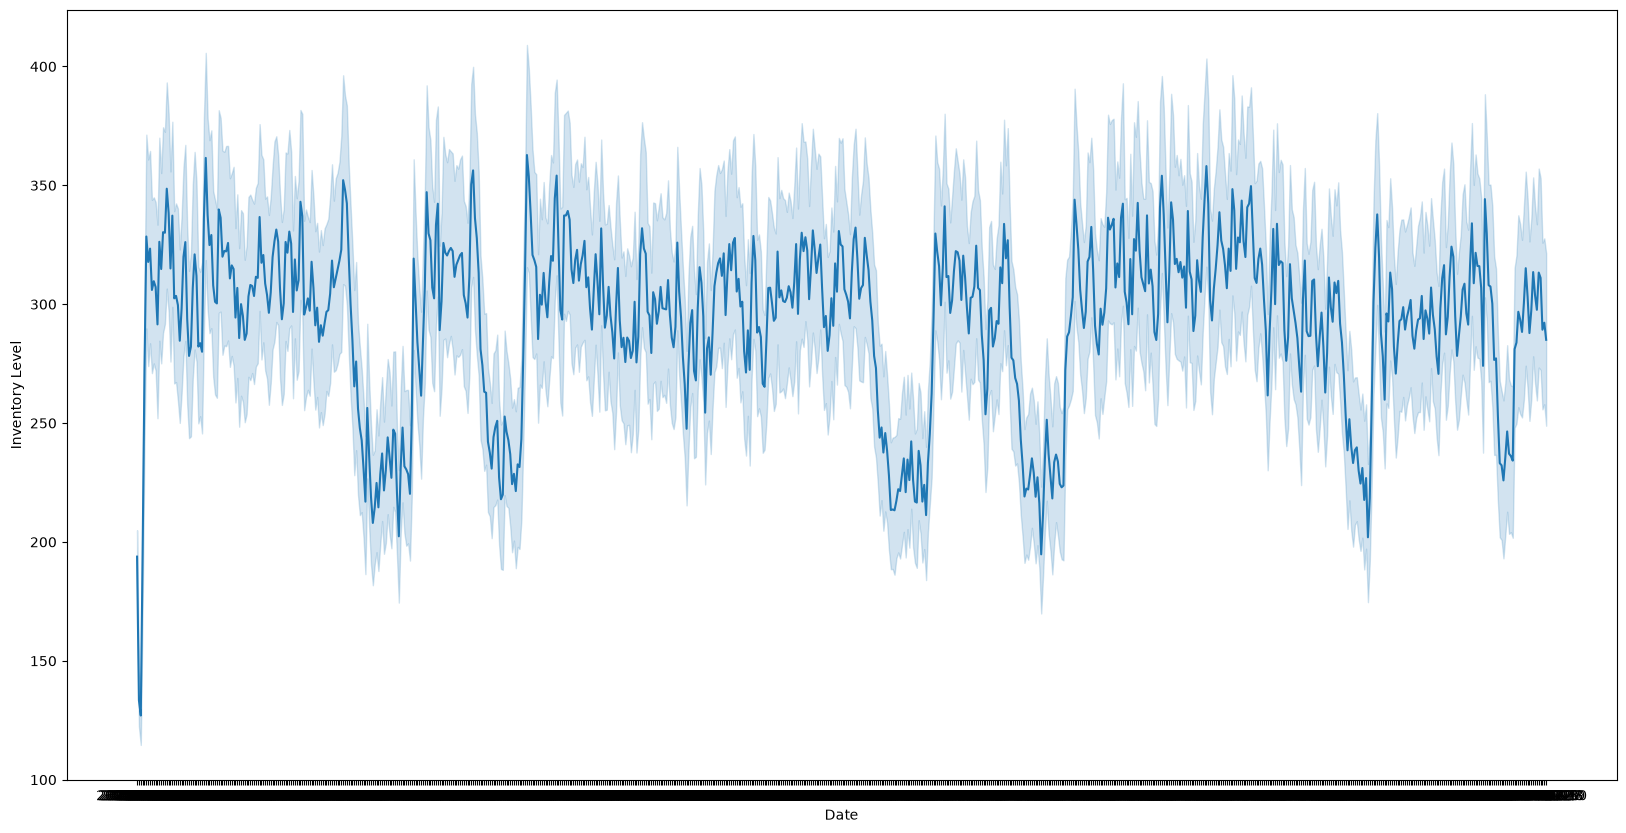

In [38]:
plt.figure(figsize=(20,10))
sns.lineplot(data=df, x='Date', y='Inventory Level')

This line chart show how the Inventory Level changes overtime. The large dips at somewhat regular intervals leads me to wonder if seasonality is involved. 

<Axes: xlabel='Date', ylabel='Demand'>

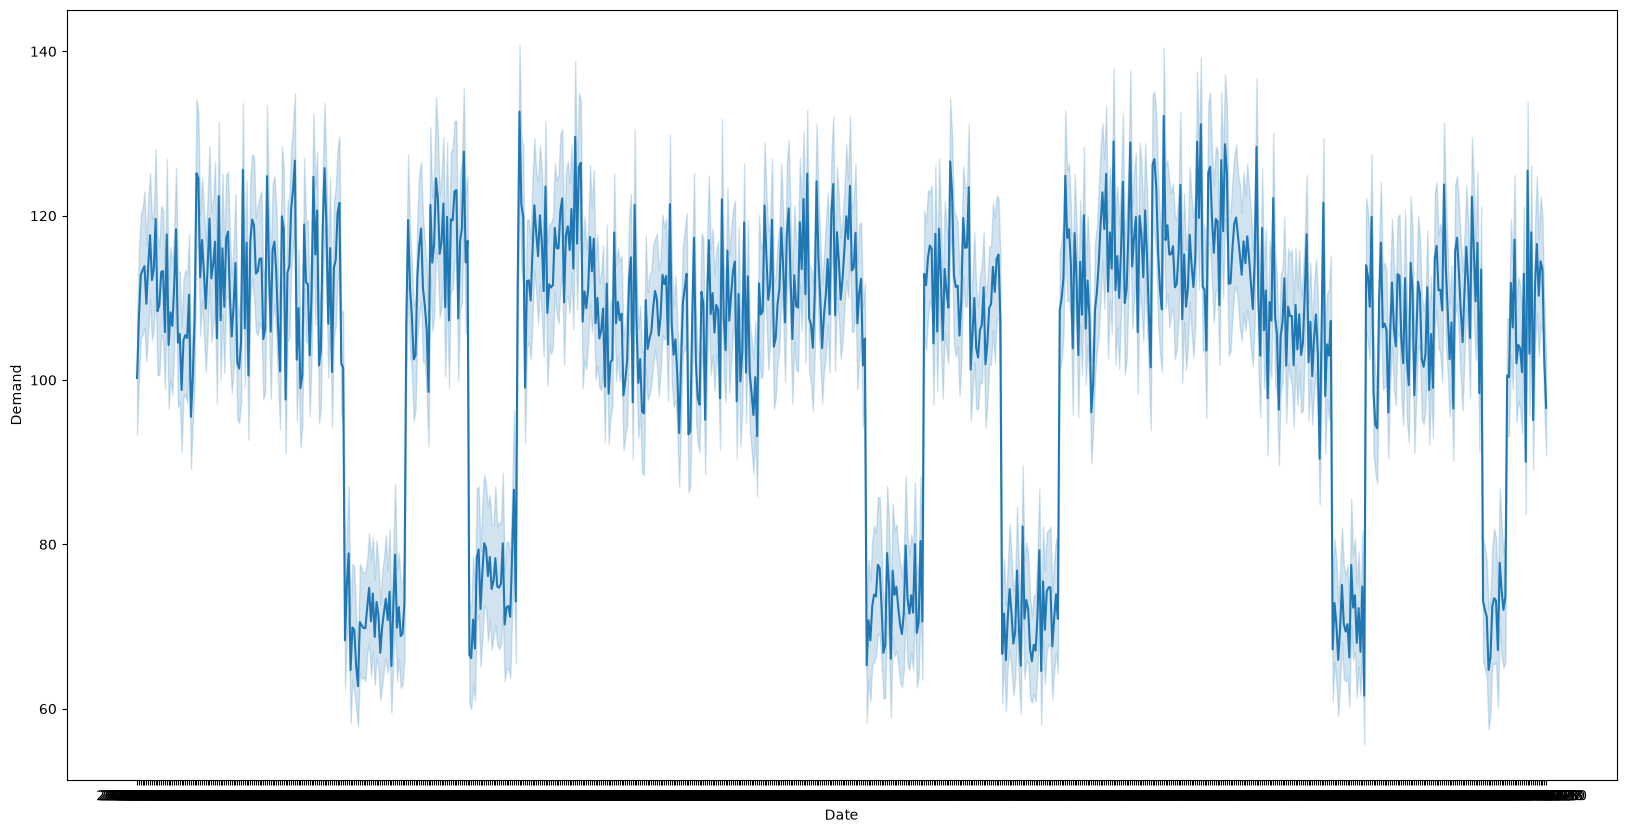

In [39]:
plt.figure(figsize=(20,10))
sns.lineplot(data=df, x='Date', y='Demand')

This line chart has a similar shape to the Inventory Level chart. This leads me to believe there is a possible underlying relationship. Additionally, this reinforces my possible ideas regarding seasonality. 

<Axes: xlabel='Demand', ylabel='Inventory Level'>

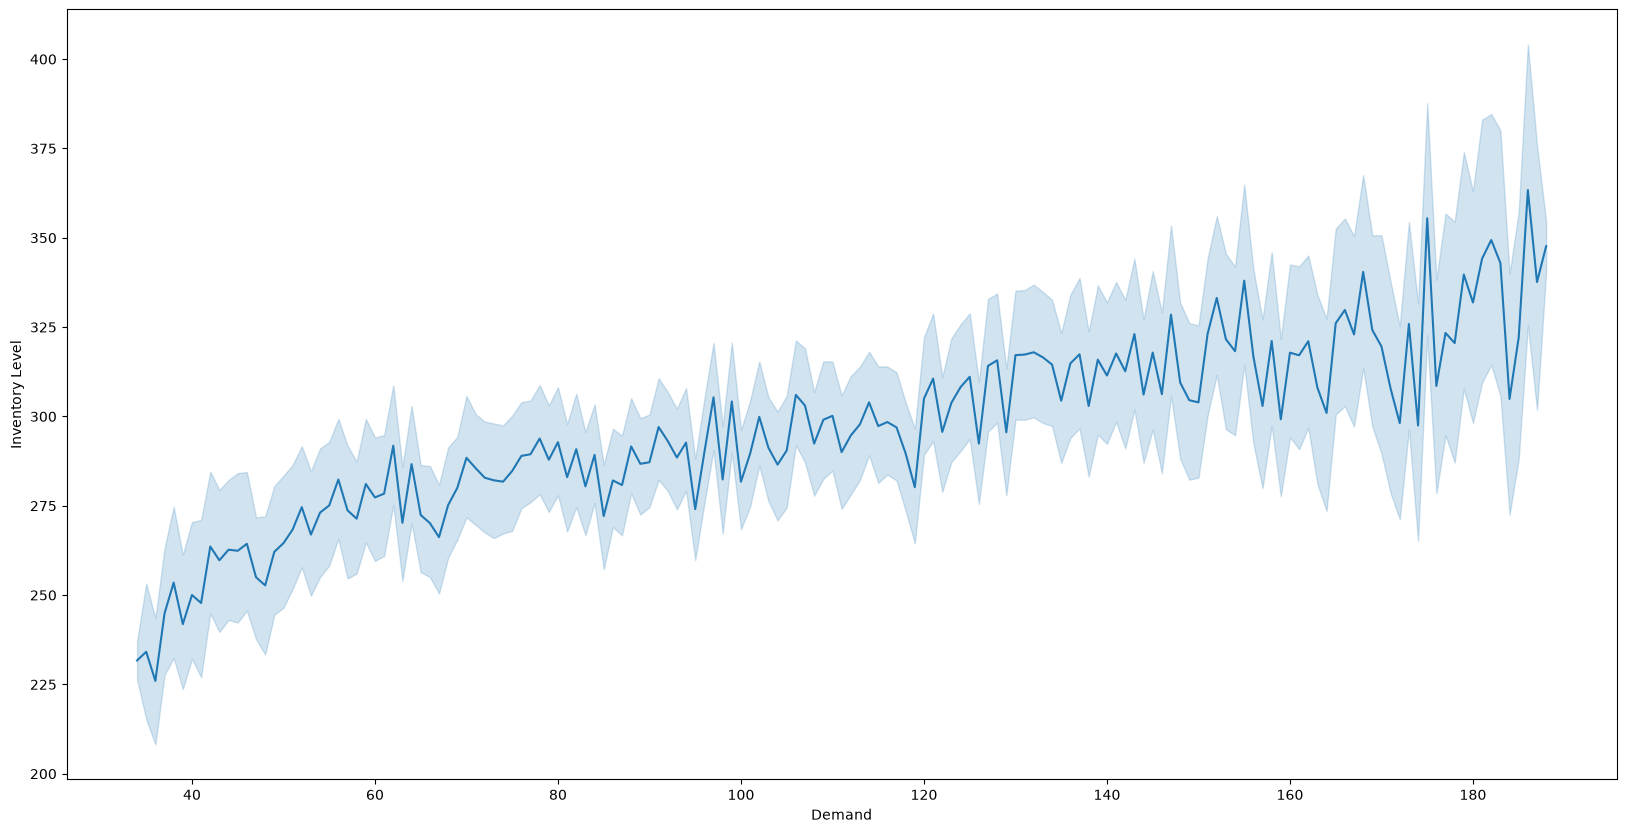

In [40]:
plt.figure(figsize=(20,10))
sns.lineplot(data=df, x='Demand', y='Inventory Level')

While not perfectly smooth this chart is showing a roughly positive relationship between Demand and the target variable of Inventory Level. This will be helpful when considering predictions. 

<Axes: xlabel='Demand', ylabel='Units Sold'>

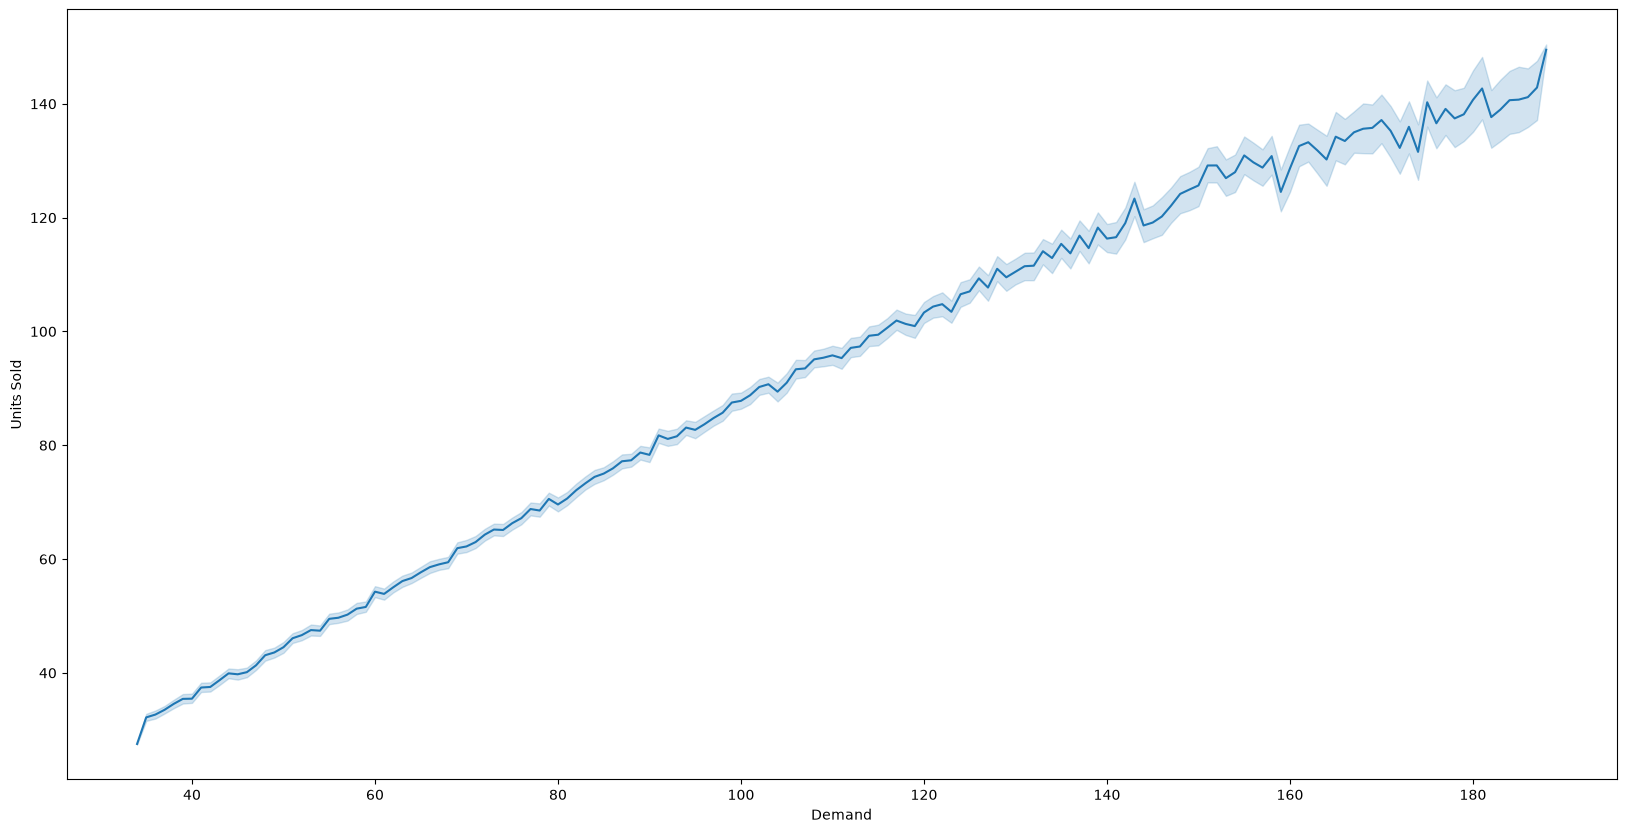

In [41]:
plt.figure(figsize=(20,10))
sns.lineplot(data=df, x='Demand', y='Units Sold')

This chart shows a strong positive relationship between Demand and Units Sold. 

#### Correlation

<Axes: >

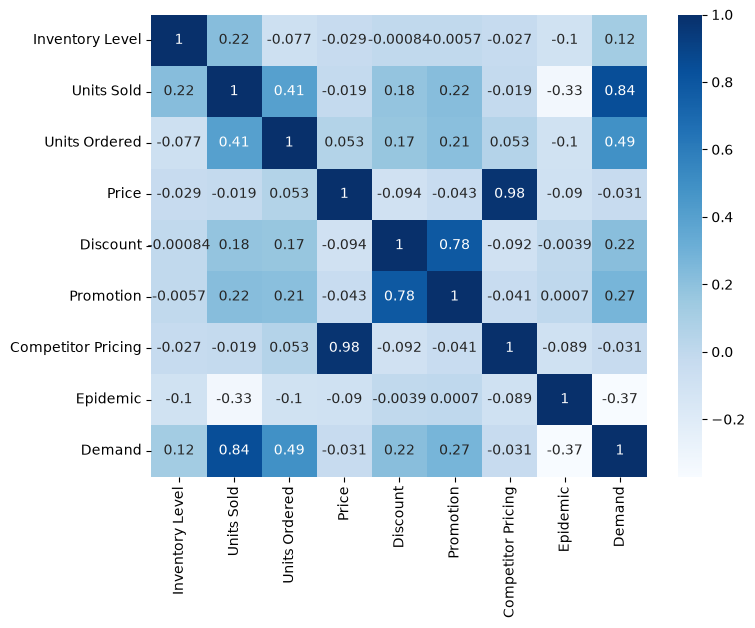

In [42]:
plt.figure(figsize=(8,6))
correlation_matrix = df.corr(numeric_only=True) 
sns.heatmap(correlation_matrix, annot=True, cmap='Blues')

My main concern or surprise comes from this heatmap where I can see that my target variable of Inventory Level does not have as of high of a correlation with the other variables as I had originally assumed. This is causing me to question if I will need to pivot my project or consider other variables more highly. 

### Determining the highest demanded products

In [43]:
high_demand = df.groupby('Product ID')['Demand'].sum()

calculating demand of products tied to the Product ID.

In [44]:
highest_demand = high_demand.sort_values(ascending = False)
highest_demand.head()


Product ID
P0009    442197
P0013    432619
P0007    430567
P0004    430196
P0002    419622
Name: Demand, dtype: int64

Identifying the most popular products by sorting the sum of demand from highest to lowest. 

## Engineering Features for the Baseline Model 

### Splitting the data 80/20

In [45]:
# Splitting the day a into X and y 
X = df[['Demand']]
y = df['Units Sold']

In [46]:
# Splitting the data into training and testing
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, shuffle=False)

In [47]:
# Checking the shape of the training and testing sets

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(60800, 1) (60800,)
(15200, 1) (15200,)


For this phase, dummy variables were not created for categorical features becuase the required features for the model that will be created are numerical. Additionally, scaling was not performed on the data because the selected Linear Regression model does not require these steps to function. When splitting my data I used a traditional 80/20 split so that the model would have data to train with and a set of data to test the performance of the model. When splitting my data I removed the shuffling and randomization becuase I want the data to be tested chronologically and have the test data be the most recent observations to appropriately measure the prediction capabilities of the model.
 

## Training the Baseline Model 

In [48]:
# Creating a Linear Regression Model
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

In [49]:
# Training the model with the training set
lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.78]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Demand']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,7.449
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [50]:
# Predicting on the testing set with y_prediction being the predicted values from the feature values
y_prediction = lr.predict(X_test)

In [51]:
print("Slope:", lr.coef_[0])

Slope: 0.7769485811136511


#### Justification 

I chose the linear regression as a basic starting point for more complex models to be compared to in the future. I chose this model because of its simplicity and ease when seeing basic trends and interpreting results. This model clearly illsutrates the relationship between the preselected features and will allow room for growth with more complex models that include more variables. 

## Evaluate Performance 

Text(0.5, 1.0, 'Predicted vs. Actual Values')

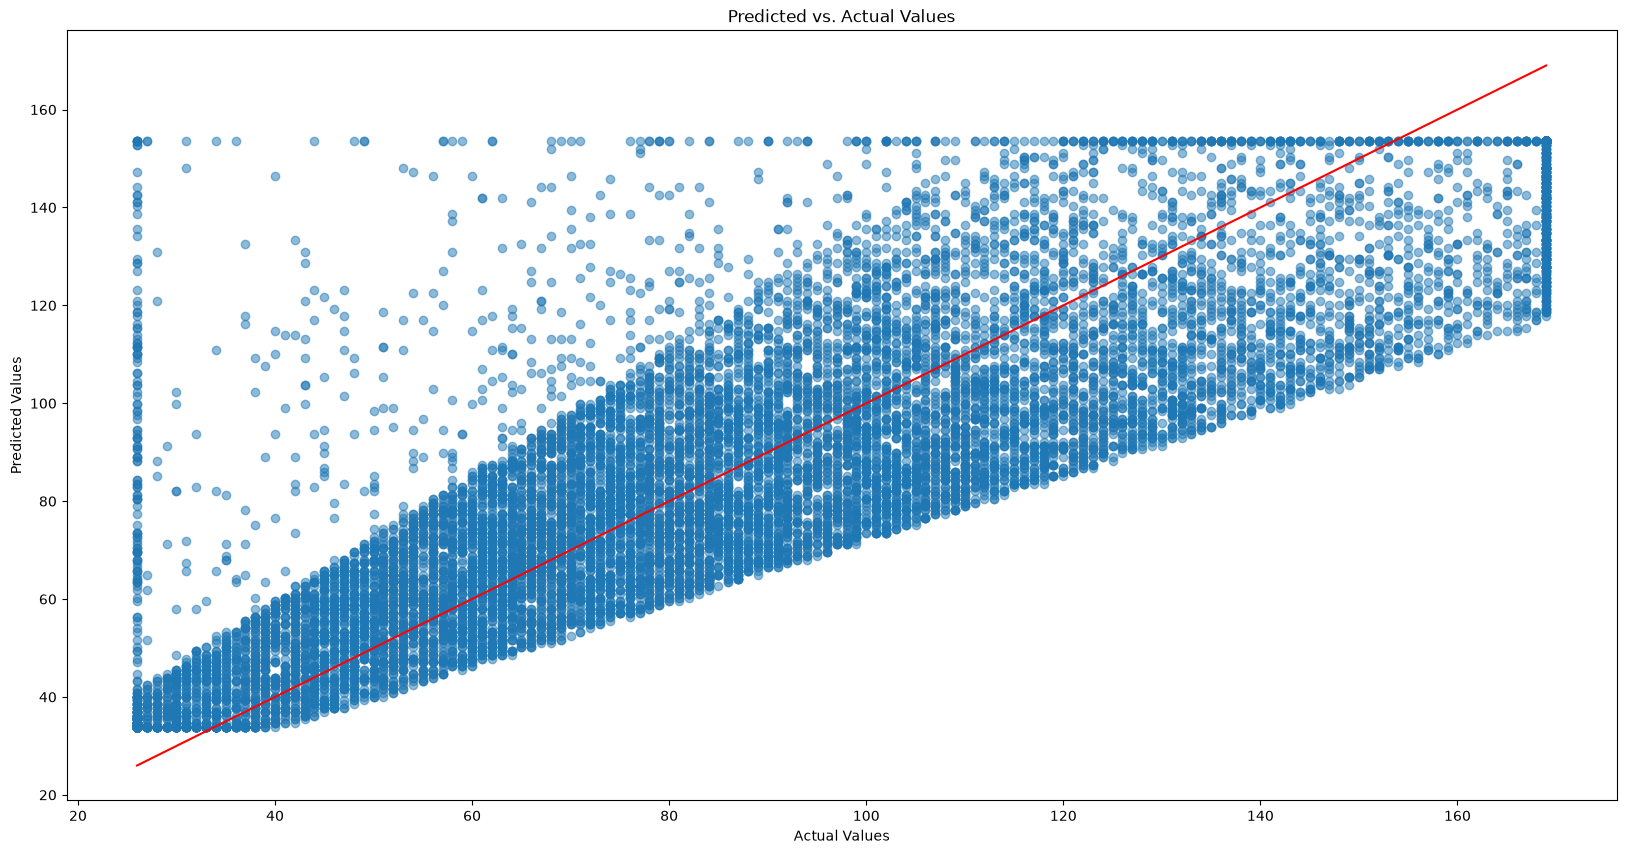

In [52]:
# Plotting the predicted versus the actual values 
plt.figure(figsize=(20,10))
plt.scatter(y_test, y_prediction, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Predicted vs. Actual Values")

In [53]:
# Evaluate performance of the model 
from sklearn.metrics import root_mean_squared_error, mean_absolute_error,r2_score
rmse = root_mean_squared_error(y_test, y_prediction)
mae = mean_absolute_error(y_test, y_prediction)
r2 = r2_score(y_test, y_prediction)

print("RMSE: ", rmse)
print("MAE: ", mae)
print("R2 Score: ", r2)


RMSE:  20.5143613833147
MAE:  15.56001785782329
R2 Score:  0.706079849989778


### Metrics Evaluation
The chosen metrics demonstrate of RMSE, MAE, and R2 Score suggest that this model is reliable for the data provided and will do a moderately well job at predicting the changes in Units Sold based on the changes in Demand. The RMSE is 20.5 meaning that the predictions errors are about 20 units off from the real data with larger data points influencing this measurement. This number is driven up due to some higher values but overall the model is moderately reliable. The MAE measures the average absolute distance between predicted and actual values. The MAE is impacted less by large values than the RMSE showing the difference between the predicted and real values without the additional weight placed on extreme values. The MAE for this model is 15.6 which is expectedly lower than the RMSE and provides additional insights about prediction errors and supports the reliability of this model. The third metric of the R2 Score describes how much of the variance is explained by the features. For this model, the R2 Score is .706 meaning that 70.6% of the variance in Units Sold is explained by Demand. This percentage is moderately high showing that the model has a good fit for the data. 

### Current Findings 
My baseline model reveals a strong fit between the data recorded for Demand and the Units Ordered. This outcome was somewhat expected since these two variables had a moderately high correlation in the heatmap from the exploratory analysis. This relationship is something that can be used to answer the research question of how inventory should be adjusted by identifying the number of units that will be predicted to sell based on changes in demand. Once this information is gathered it can then be applied to inventory decisions to avoid backorders. This model provides evidence for this relationship by producing an R2 Score of 0.706 meaning that 70.6% of the variance in units sold are explained by demand. However, there are various limitations to this current model. For example, the model is fairly simplistic by only considering the demand and units sold. This is a limiting factor since variables such as seasonality, price, and promotions could impact the changes as well.